# 2da Practica Calificada CC521 - Computacion Evolutiva

**Alumno:** Luis Antonio Rojas Huaroc  
**Codigo UNI:** 20171581B  
**Profesor:** Luis Navarro

In [14]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(20171581)  # dejo una semilla con mi codigo para poder repetir resultados

## Pregunta 1

El espacio de busqueda tiene 2097152 puntos. Como es AG de codigo binario, eso me dice la longitud del cromosoma.

Si hay $2^l$ puntos, entonces:

$$2^l = 2097152 \Rightarrow l = 21$$

O sea, cada individuo es una cadena de 21 bits.

In [15]:
# 1) longitud del cromosoma
N_puntos = 2097152
l = int(np.log2(N_puntos))
print("longitud l =", l)
print("verificacion 2^l =", 2**l)

longitud l = 21
verificacion 2^l = 2097152


### a) Numero total de esquemas

En binario, en cada posicion puedo poner 0, 1 o `*` (no importa).
Entonces por cada una de las l posiciones hay 3 opciones:

$$\text{total esquemas} = 3^l = 3^{21}$$

In [16]:
total_esquemas = 3**l
print("a) Numero total de esquemas =", total_esquemas)

a) Numero total de esquemas = 10460353203


### b) Numero total de puntos de busqueda

Eso es justamente el dato que nos dan en el enunciado. Con l bits:

$$2^l = 2^{21} = 2097152$$

In [17]:
total_puntos = 2**l
print("b) Numero total de puntos de busqueda =", total_puntos)

b) Numero total de puntos de busqueda = 2097152


### c) Numero de esquemas contenidos en cada individuo

Tomo un cromosoma fijo, por ejemplo `1010...`.
En cada posicion puedo dejar el bit tal cual o poner `*`.
Son 2 opciones por posicion, asi que:

$$2^l = 2^{21}$$

Eso es lo que contiene un solo individuo.

In [18]:
esquemas_por_individuo = 2**l
print("c) Esquemas por individuo =", esquemas_por_individuo)

c) Esquemas por individuo = 2097152


### d) Cotas inferior y superior (poblacion de tamano 50)

Segun lo que hemos visto en clase, teoria de esquemas:

- **Cota inferior:** si todos los 50 individuos son iguales, la poblacion no aporta esquemas nuevos. Se queda en los del unico cromosoma: $2^l$.
- **Cota superior:** en el mejor caso, cada individuo aporta esquemas distintos, o sea $n \cdot 2^l$, pero nunca puede pasar del total de esquemas $3^l$.

Entonces:

$$2^l \leq \#\text{esquemas en la poblacion} \leq \min(n \cdot 2^l,\, 3^l)$$

In [19]:
n_pob = 50
cota_inf = 2**l
cota_sup = min(n_pob * (2**l), 3**l)

print("d) Cota inferior =", cota_inf)
print("d) Cota superior =", cota_sup)
print("(n * 2^l =", n_pob * (2**l), ", 3^l =", 3**l, ")")

d) Cota inferior = 2097152
d) Cota superior = 104857600
(n * 2^l = 104857600 , 3^l = 10460353203 )


### e) Cota inferior del numero esperado (de t a t+1)

Aqui el enunciado menciona "individuos", pero por lo que vimos de parallelismo implicito, lo que nos suelen pedir es la cota del orden de esquemas que el AG "procesa" de una generacion a la siguiente.

Esa cota inferior es del orden de $n^3$ (con n = tamano de poblacion):

$$n^3 = 50^3 = 125000$$

O sea, aunque la poblacion sea chica, el AG esta trabajando con muchos esquemas a la vez. Si el rpoblema literalmente hubiera querido individuos de la poblacion nueva, serian n = 50 (se generan 50 por generacion), pero creo que apunta al $n^3$.

In [20]:
cota_e = n_pob**3
print("e) Cota inferior (orden n^3) =", cota_e)

e) Cota inferior (orden n^3) = 125000


## Pregunta 2

Hay que minimizar $f(x,y,z)$ (la funcion en si no nos la dan, solo el diseño de la codificación).

| Variable | Rango | Precision |
|---|---|---|
| x | [-20.0, 125.0] | 0.5 |
| y | [0, 1.2e6] | 10000 |
| z | [-0.1, 1.0] | 0.001 |

Uso **codificación de punto fijo**, cada variable se mapea a un entero binario y luego **concateno** los tres bloques: `[bits_x | bits_y | bits_z]`.

Para calcular bits de cada variable pido que el paso del mapeo sea menor o igual a la precisión:

$$\frac{b_i - a_i}{2^{l_i} - 1} \leq \text{precision}_i$$

o sea

$$2^{l_i} - 1 \geq \frac{b_i - a_i}{\text{precision}_i}$$

In [21]:
def bits_necesarios(a, b, precision):
    # cuantos valores discretos necesito como mínimo
    necesito = (b - a) / precision
    li = 0
    while (2**li - 1) < necesito:
        li = li + 1
    paso = (b - a) / (2**li - 1)
    return li, necesito, paso

lx, nx, pasox = bits_necesarios(-20.0, 125.0, 0.5)
ly, ny, pasoy = bits_necesarios(0.0, 1.2e6, 10000.0)
lz, nz, pasoz = bits_necesarios(-0.1, 1.0, 0.001)

print("x: rango/prec =", nx, "-> lx =", lx, "paso =", pasox)
print("y: rango/prec =", ny, "-> ly =", ly, "paso =", pasoy)
print("z: rango/prec =", nz, "-> lz =", lz, "paso =", pasoz)
print("Total de bits =", lx + ly + lz)

x: rango/prec = 290.0 -> lx = 9 paso = 0.2837573385518591
y: rango/prec = 120.0 -> ly = 7 paso = 9448.818897637795
z: rango/prec = 1100.0 -> lz = 11 paso = 0.0005373717635564241
Total de bits = 27


Me salio:

- $l_x = 9$ (porque $2^8-1=255 < 290$ y $2^9-1=511 \geq 290$)
- $l_y = 7$ (porque $2^6-1=63 < 120$ y $2^7-1=127 \geq 120$)
- $l_z = 11$ (porque $2^{10}-1=1023 < 1100$ y $2^{11}-1=2047 \geq 1100$)

**Numero minimo de bits = 9 + 7 + 11 = 27**

El mapeo (decodificacion) es:

$$x = a_x + \frac{\text{int}(bits_x)}{2^{l_x}-1}(b_x - a_x)$$

igual para y y z.

Para codificar un valor real a bits uso el inverso y redondeo al entero mas cercano.

In [22]:
def codificar(valor, a, b, li):
    # llevo el real al entero en [0, 2^li - 1]
    entero = (valor - a) / (b - a) * (2**li - 1)
    entero = int(round(entero))
    if entero < 0:
        entero = 0
    if entero > (2**li - 1):
        entero = 2**li - 1
    cadena = format(entero, '0{}b'.format(li))
    return entero, cadena

def decodificar(entero, a, b, li):
    return a + entero / (2**li - 1) * (b - a)

def codificar_punto(x, y, z):
    ix, sx = codificar(x, -20.0, 125.0, lx)
    iy, sy = codificar(y, 0.0, 1.2e6, ly)
    iz, sz = codificar(z, -0.1, 1.0, lz)
    cromosoma = sx + sy + sz
    return cromosoma, (ix, iy, iz), (sx, sy, sz)

# puntos del enunciado
# el segundo punto lo interpreto como (125.0, 1.2e6, 1.0)
puntos = [
    (-20.0, 0.0, -0.1),
    (125.0, 1.2e6, 1.0),
    (50.0, 100000.0, 0.597),
]

for p in puntos:
    crom, enteros, bloques = codificar_punto(*p)
    print("Punto", p)
    print("  enteros (x,y,z) =", enteros)
    print("  bloque x =", bloques[0])
    print("  bloque y =", bloques[1])
    print("  bloque z =", bloques[2])
    print("  cromosoma (27 bits) =", crom)
    # chequeo rapido decodificando
    xd = decodificar(enteros[0], -20.0, 125.0, lx)
    yd = decodificar(enteros[1], 0.0, 1.2e6, ly)
    zd = decodificar(enteros[2], -0.1, 1.0, lz)
    print("  decodificado approx =", (xd, yd, zd))
    print()

Punto (-20.0, 0.0, -0.1)
  enteros (x,y,z) = (0, 0, 0)
  bloque x = 000000000
  bloque y = 0000000
  bloque z = 00000000000
  cromosoma (27 bits) = 000000000000000000000000000
  decodificado approx = (-20.0, 0.0, -0.1)

Punto (125.0, 1200000.0, 1.0)
  enteros (x,y,z) = (511, 127, 2047)
  bloque x = 111111111
  bloque y = 1111111
  bloque z = 11111111111
  cromosoma (27 bits) = 111111111111111111111111111
  decodificado approx = (125.0, 1200000.0, 1.0)

Punto (50.0, 100000.0, 0.597)
  enteros (x,y,z) = (247, 11, 1297)
  bloque x = 011110111
  bloque y = 0001011
  bloque z = 10100010001
  cromosoma (27 bits) = 011110111000101110100010001
  decodificado approx = (50.088062622309195, 103937.00787401575, 0.596971177332682)



### Cadenas obtenidas

1. $(-20, 0, -0.1)$ = limites inferiores -> todo ceros:
   `000000000 0000000 00000000000`
   -> `000000000000000000000000000`

2. $(125.0, 1.2 \times 10^6, 1.0)$ = limites superiores -> todo unos:
   `111111111 1111111 11111111111`
   -> `111111111111111111111111111`

3. $(50, 100000, 0.597)$:
   - x -> 247 -> `011110111`
   - y -> 11 -> `0001011`
   - z -> 1297 -> `10100010001`
   -> `011110111000101110100010001`

El punto 3 no cae exacto en la grilla (es normal por la precision), pero queda bien cerca.

## Pregunta 3

Hallar el maximo de $f(x) = 3x^{10}$ con un algoritmo genetico simple.

### Justificación de parametros

**Dominio:** como $3x^{10}$ crece si $|x|$ crece, sin limites el maximo se va a infinito. Para que tenga sentido el problema tomo $x \in [0, 1]$. Ahi el maximo teorico es en $x=1$, con $f(1)=3$.

**Precision:** uso $0.001$. Entonces:

$$\frac{1-0}{2^{l}-1} \leq 0.001 \Rightarrow 2^{l}-1 \geq 1000 \Rightarrow l = 10$$

(porque $2^{10}-1=1023 \geq 1000$).

**n (tamaño de población):** uso $n=50$, igual que en el laboratorio dirigido. No es tan chica como para estancarse rapido ni tan grande como para tardar.

**ps (seleccion):** seleccion proporcional al fitness (ruleta), que es lo tipico del AG simple. La probabilidad de elegir al individuo i es:

$$p_s(i) = \frac{f_i}{\sum_j f_j}$$

**pc (cruzamiento):** $0.8$. permite mezclar bastante sin destruir todo.

**pm (mutacion):** $0.01$. Como l=10, mas o menos $1/l$, que es una regla practica para no mutar de mas.

**Generaciones:** 80, suficiente para ver convergencia.

Operadores: cruzamiento de un punto y mutacion bit a bit, como en el laboratorio dirigida.

In [23]:
# ----- parametros -----
DNA_SIZE = 10          # l bits (precision 0.001 en [0,1])
POP_SIZE = 50          # n
PC = 0.8               # probabilidad de cruzamiento
PM = 0.01              # probabilidad de mutacion
N_GEN = 80             # generaciones
X_MIN, X_MAX = 0.0, 1.0

def fitness(x):
    # f(x) = 3 * x^10
    return 3.0 * (x ** 10)

def decode(pop):
    # cada fila es un cromosoma binario -> real en [0,1]
    # interpreto la cadena como entero y mapeo lineal
    potencias = 2 ** np.arange(DNA_SIZE)[::-1]
    enteros = pop.dot(potencias)
    x = X_MIN + enteros / (2**DNA_SIZE - 1) * (X_MAX - X_MIN)
    return x

def seleccion_ruleta(pop, fit):
    # ps proporcional al fitness
    # si por alguna razon el fitness total es 0, elijo al azar
    total = fit.sum()
    if total <= 0:
        idx = np.random.randint(0, POP_SIZE, size=POP_SIZE)
    else:
        probs = fit / total
        idx = np.random.choice(np.arange(POP_SIZE), size=POP_SIZE, p=probs)
    return pop[idx].copy()

def cruzamiento(pop):
    # cruzamiento de un punto
    nueva = pop.copy()
    for i in range(0, POP_SIZE, 2):
        if i + 1 >= POP_SIZE:
            break
        if np.random.rand() < PC:
            punto = np.random.randint(1, DNA_SIZE)
            p1 = nueva[i].copy()
            p2 = nueva[i+1].copy()
            nueva[i] = np.concatenate((p1[:punto], p2[punto:]))
            nueva[i+1] = np.concatenate((p2[:punto], p1[punto:]))
    return nueva

def mutacion(pop):
    # muto bit a bit con probabilidad pm
    mascara = np.random.rand(POP_SIZE, DNA_SIZE) < PM
    pop_mut = pop.copy()
    pop_mut[mascara] = 1 - pop_mut[mascara]
    return pop_mut

# poblacion inicial aleatoria
pop = np.random.randint(0, 2, size=(POP_SIZE, DNA_SIZE))

hist_mejor = []
hist_prom = []
hist_x_mejor = []

mejor_x = None
mejor_f = -1.0
mejor_crom = None

for g in range(N_GEN):
    x = decode(pop)
    fit = fitness(x)

    i_best = np.argmax(fit)
    hist_mejor.append(fit[i_best])
    hist_prom.append(fit.mean())
    hist_x_mejor.append(x[i_best])

    if fit[i_best] > mejor_f:
        mejor_f = fit[i_best]
        mejor_x = x[i_best]
        mejor_crom = pop[i_best].copy()

    # AG simple: seleccion -> cruzamiento -> mutacion
    pop = seleccion_ruleta(pop, fit)
    pop = cruzamiento(pop)
    pop = mutacion(pop)

print("Mejor x encontrado =", mejor_x)
print("Mejor f(x) =", mejor_f)
print("Cromosoma =", ''.join(map(str, mejor_crom)))
print("f(1) teorico =", fitness(1.0))
print("ultimo mejor de la corrida =", hist_mejor[-1])
print("ultimo promedio =", hist_prom[-1])

Mejor x encontrado = 1.0
Mejor f(x) = 3.0
Cromosoma = 1111111111
f(1) teorico = 3.0
ultimo mejor de la corrida = 3.0
ultimo promedio = 2.5592104322615077


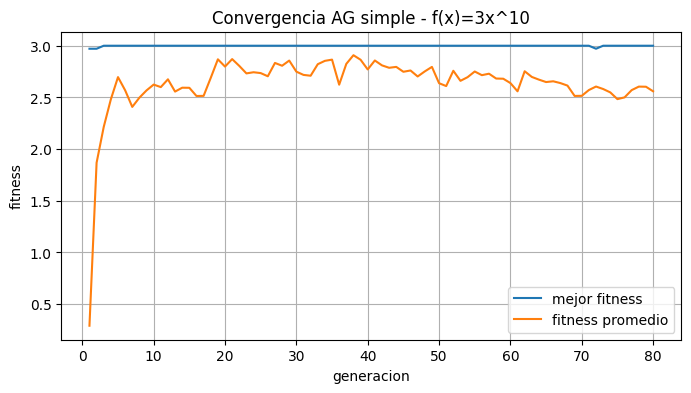

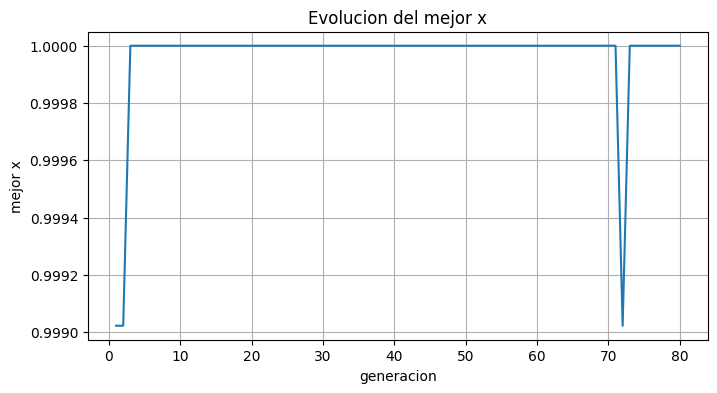

In [24]:
# grafico de convergencia
gens = np.arange(1, N_GEN + 1)

plt.figure(figsize=(8, 4))
plt.plot(gens, hist_mejor, label="mejor fitness")
plt.plot(gens, hist_prom, label="fitness promedio")
plt.xlabel("generacion")
plt.ylabel("fitness")
plt.title("Convergencia AG simple - f(x)=3x^10")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(gens, hist_x_mejor)
plt.xlabel("generacion")
plt.ylabel("mejor x")
plt.title("Evolucion del mejor x")
plt.grid(True)
plt.show()

La curva del mejor fitness deberia subir rapido hacia 3 y el mejor x acercarse a 1. El promedio tambien sube, aunque un poco mas lento / con ruido por la mutacion.

Si se vuelve a ejecutar, puede variar un poco por la aleatoriedad, pero con estos parametros sabemos que casi siempre va a terminar cerca del optimo.